# Actividad 4 · Evaluación del recomendador Softtek
**Isaac Esquivel Ruiz · Universidad Tecmilenio**  
Sistemas y tecnologías de administración del conocimiento

Evaluación del mismo recomendador de la actividad 3. Corpus simulado de 30 documentos; no representa información interna real de Softtek. Este notebook incluye los archivos necesarios para ejecutarse en Colab sin subir un CSV. La copia externa del corpus se entrega para facilitar su revisión.

## 1. Preparación y conservación del sistema
Se conserva el código original y su corpus, extraídos del notebook ejecutado de la actividad 3. No se cambian limpieza, TF-IDF, coseno ni K=5. Los juicios de relevancia se guardan aparte del algoritmo.

In [1]:
import importlib.util, subprocess, sys
paquetes = {'sklearn':'scikit-learn', 'pandas':'pandas', 'numpy':'numpy', 'matplotlib':'matplotlib'}
faltantes = [pkg for mod,pkg in paquetes.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *faltantes])
from pathlib import Path
BASE = Path.cwd() / 'actividad4_resultados'
BASE.mkdir(exist_ok=True)
print('Carpeta de trabajo:', BASE)

Carpeta de trabajo: /content/actividad4_resultados


In [2]:
# Archivos íntegros de trabajo; el recomendador original no se modifica.
ARCHIVOS = {'corpus.csv': 'id,title,text,category\nDOC001,Política de acceso y autenticación de cuentas,Toda cuenta de usuario debe tener acceso autorizado según su función. El acceso al portal requiere contraseña personal y autenticación multifactor. La mesa de servicio verifica la identidad antes de desbloquear una cuenta o restablecer credenciales. Los permisos deben revisarse cuando cambia el puesto del usuario. Las cuentas compartidas no están permitidas.,Políticas y procesos\nDOC002,Ticket: cuenta bloqueada en el portal,"Un usuario no pudo acceder al portal después de varios intentos con una contraseña incorrecta. Soporte verificó su identidad, revisó el bloqueo de la cuenta y restableció el acceso. Se confirmó la autenticación multifactor y se pidió al usuario actualizar las credenciales guardadas. El incidente quedó cerrado después de validar el inicio de sesión.",Soporte e incidentes\nDOC003,Proceso de alta y baja de permisos,"El responsable solicita el alta de la cuenta indicando los permisos requeridos. La mesa de servicio valida la autorización y habilita el acceso mínimo. Cuando termina la relación laboral, se desactiva la cuenta y se revocan las sesiones. Cada cambio de permisos debe quedar registrado para que la revisión de acceso identifique privilegios innecesarios.",Políticas y procesos\nDOC004,FAQ: recuperación de contraseña y segundo factor,"Si el usuario olvida su contraseña, debe solicitar la recuperación de acceso por el canal autorizado. Soporte verifica la identidad antes de restablecer la cuenta. Si pierde el segundo factor de autenticación, se revoca el dispositivo anterior y se registra uno nuevo. Nunca se solicita enviar contraseñas por correo para recuperar el acceso.",Operación y guías\nDOC005,Ticket: permisos insuficientes después de un cambio de puesto,"La cuenta de una analista inició sesión correctamente, pero no pudo abrir una sección del portal. La revisión encontró permisos del puesto anterior. Soporte recibió la autorización del responsable y ajustó el acceso según la nueva función. No fue necesario cambiar la contraseña porque la autenticación funcionaba. Se validó el acceso con la usuaria.",Soporte e incidentes\nDOC006,Revisión mensual de cuentas privilegiadas,"La revisión de acceso compara las cuentas privilegiadas con las autorizaciones vigentes. El equipo identifica cuentas inactivas, permisos excesivos y autenticación multifactor deshabilitada. Cada hallazgo se asigna a un responsable. Antes de retirar un permiso se verifica su uso operativo. La revisión conserva evidencia de las cuentas corregidas y de las excepciones autorizadas.",Operación y guías\nDOC007,Política de respaldos y restauración de datos,Los respaldos de datos deben ejecutarse según el calendario autorizado. El equipo verifica el resultado de cada copia y conserva la retención definida para el servicio. Un respaldo exitoso no demuestra que pueda restaurarse. Por eso se programan pruebas de restauración y se revisa la integridad de los archivos recuperados antes de considerar protegida la información.,Políticas y procesos\nDOC008,Ticket: respaldo nocturno fallido por falta de espacio,"El respaldo nocturno de la base de datos falló porque el repositorio de copias no tenía espacio disponible. Soporte revisó la retención, liberó copias vencidas autorizadas y repitió el respaldo. Después ejecutó una restauración de prueba y verificó la integridad de los datos. Se configuró una alerta de capacidad para evitar que el incidente se repita.",Soporte e incidentes\nDOC009,Proceso de restauración de un respaldo,Para restaurar datos se identifica la copia de respaldo correspondiente al punto de recuperación aprobado. La restauración se realiza primero en un entorno aislado. Se valida la integridad de archivos y registros antes de sustituir información operativa. El responsable registra el tiempo de recuperación y cualquier pérdida observada para ajustar el plan de respaldos.,Políticas y procesos\nDOC010,FAQ: diferencia entre respaldo completo e incremental,"El respaldo completo copia todos los datos seleccionados. El respaldo incremental guarda los cambios desde la copia anterior y requiere la cadena correspondiente para restaurar. Si falta una copia, la recuperación puede quedar incompleta. Antes de modificar la retención, el equipo debe comprobar que conserva los respaldos necesarios para reconstruir los datos.",Operación y guías\nDOC011,Ticket: restauración incompleta por copia dañada,"Durante una restauración de prueba se detectaron archivos dañados en una copia de respaldo. El equipo revisó la integridad, seleccionó una copia anterior y repitió la recuperación. Los datos recuperados se compararon con el inventario esperado. Se abrió una revisión del almacenamiento y se suspendió la eliminación de respaldos hasta asegurar una cadena de recuperación válida.",Soporte e incidentes\nDOC012,Bitácora de pruebas de recuperación,"La bitácora registra las pruebas de restauración de respaldos, la fecha de cada copia y el responsable de la recuperación. Incluye la integridad de los datos recuperados y el tiempo empleado. Cuando una prueba supera el objetivo de recuperación, se revisan el tamaño del respaldo, la capacidad del repositorio y las instrucciones de restauración.",Operación y guías\nDOC013,Política de despliegue y reversión de versiones,"El despliegue de una nueva versión requiere pruebas aprobadas y una ventana de cambio. Antes de publicar se conserva la versión anterior y se documenta el procedimiento de reversión. Si aparecen errores críticos, el responsable detiene el despliegue y ejecuta el rollback autorizado. La decisión debe considerar el impacto en el servicio y los cambios de datos.",Políticas y procesos\nDOC014,Ticket: errores después del despliegue de una versión,"Después del despliegue de una nueva versión, el portal comenzó a devolver errores. El equipo comparó los registros con la versión anterior y detectó una configuración incompatible. Se ejecutó la reversión mediante rollback y se verificó la recuperación del servicio. El despliegue quedó suspendido hasta repetir las pruebas de compatibilidad y obtener una nueva autorización.",Soporte e incidentes\nDOC015,Proceso de autorización de cambios de software,"La solicitud de cambio identifica la versión, el objetivo del despliegue y el impacto esperado. El responsable revisa las pruebas, la ventana de mantenimiento y el procedimiento de reversión. No se autoriza una publicación sin evidencia de validación. Si el cambio modifica datos, el plan explica cómo tratar esa modificación durante un posible rollback.",Políticas y procesos\nDOC016,Guía de rollback ante una publicación defectuosa,Para realizar el rollback se detiene la publicación y se identifica la última versión estable. La reversión restaura la configuración compatible y requiere revisar los cambios de datos. Después se ejecutan pruebas de disponibilidad y se confirman los registros de error. El despliegue solo se reanuda cuando la causa de la falla ha sido corregida.,Operación y guías\nDOC017,Ticket: despliegue detenido por pruebas de integración,Las pruebas de integración detectaron errores antes de publicar la nueva versión. El equipo detuvo el despliegue y conservó la versión estable en producción. No fue necesario ejecutar rollback porque la publicación no había ocurrido. Se corrigió la incompatibilidad y se solicitaron nuevas pruebas antes de aprobar otra ventana de cambio.,Soporte e incidentes\nDOC018,Lista de verificación de una liberación,"Antes del despliegue, la lista verifica la versión aprobada, las pruebas terminadas y la disponibilidad del responsable. También confirma que existe un procedimiento de reversión y una versión anterior recuperable. Después de la publicación se observan errores y tiempos de respuesta. Si la validación falla, se evalúa el rollback según el impacto del cambio.",Operación y guías\nDOC019,Política de atención de correos sospechosos,"Los mensajes que soliciten datos sensibles o contengan enlaces inesperados deben reportarse como posible phishing. El usuario no debe abrir archivos sospechosos ni responder al remitente. Seguridad conserva las cabeceras del correo para analizar el origen. Si hubo interacción con el enlace, se revisan el equipo y las credenciales expuestas antes de cerrar la alerta.",Políticas y procesos\nDOC020,Ticket: correo de phishing con enlace externo,Una persona recibió un correo que simulaba una notificación urgente y solicitaba abrir un enlace externo. Reportó el mensaje sin interactuar. Seguridad analizó el remitente y confirmó el intento de phishing. El enlace fue bloqueado y el mensaje se retiró de otros buzones. Se compartieron indicadores del correo para reconocer intentos similares.,Soporte e incidentes\nDOC021,Proceso de aislamiento de equipos comprometidos,"Cuando se detecta malware, el equipo se aísla de la red según el procedimiento autorizado. Seguridad conserva evidencias y analiza archivos sospechosos antes de la limpieza. El responsable revisa si el incidente comenzó con un correo de phishing. La reconexión requiere verificar que se eliminó la amenaza y que no persisten indicadores de compromiso.",Políticas y procesos\nDOC022,FAQ: señales de un mensaje fraudulento,"Un correo de phishing puede usar urgencia, un remitente parecido al legítimo o enlaces que llevan a un dominio diferente. Los archivos inesperados también requieren revisión. El usuario debe reportar el mensaje sospechoso y conservarlo para análisis. No todos los errores de redacción prueban fraude; seguridad debe evaluar el contexto y el destino del enlace.",Operación y guías\nDOC023,Ticket: archivo malicioso abierto desde un correo,"El usuario abrió un archivo adjunto de un correo sospechoso y se generó una alerta de malware. Seguridad aisló el equipo, conservó las evidencias y analizó el archivo. La investigación identificó una campaña de phishing. Se revisaron otros buzones y se bloquearon los indicadores detectados antes de autorizar la reconexión del dispositivo.",Soporte e incidentes\nDOC024,Bitácora de simulación de phishing,"La simulación de phishing registra cuántos usuarios reportaron el correo sospechoso y cuántos abrieron el enlace de prueba. El objetivo es identificar necesidades de capacitación, sin publicar resultados individuales. El equipo revisa los mensajes utilizados y explica señales de riesgo. Las métricas se comparan entre ejercicios de alcance similar para evitar conclusiones engañosas.",Operación y guías\nDOC025,Política de monitoreo de rendimiento,"El monitoreo de rendimiento observa latencia, uso de CPU y consumo de memoria de los servicios. Las alertas se definen según la carga habitual y el impacto para los usuarios. Una alerta de CPU no demuestra por sí sola una falla. El equipo debe correlacionar métricas y registros antes de reiniciar un servicio o ampliar capacidad.",Políticas y procesos\nDOC026,Ticket: latencia elevada por saturación de CPU,"El servicio mostró latencia elevada durante una carga de trabajo extraordinaria. El monitoreo detectó saturación de CPU y aumento del tiempo de respuesta. El equipo identificó un proceso intensivo, ajustó la concurrencia y verificó las métricas posteriores. No se atribuyó el problema a memoria porque su consumo permaneció dentro del comportamiento habitual.",Soporte e incidentes\nDOC027,Proceso de análisis de capacidad,"El análisis de capacidad compara la carga prevista con las métricas de CPU, memoria y latencia. Se revisan tendencias de uso y periodos de saturación antes de ampliar recursos. El responsable define una prueba de carga para verificar el cambio. La decisión debe equilibrar rendimiento, costo y margen operativo, sin basarse en un único pico de consumo.",Políticas y procesos\nDOC028,Guía de diagnóstico de lentitud del servicio,"Cuando un servicio presenta lentitud se revisan la latencia, la CPU, la memoria y las consultas a la base de datos. El diagnóstico compara métricas durante periodos normales y durante la falla. Si el problema coincide con mayor carga, se prueba una reducción controlada de concurrencia. Toda intervención debe validar el tiempo de respuesta posterior.",Operación y guías\nDOC029,Ticket: consumo creciente de memoria,El monitoreo registró consumo creciente de memoria y aumento de latencia después de varias horas de operación. La CPU se mantuvo estable. El equipo analizó el proceso y encontró objetos que no se liberaban. Se aplicó una corrección y se repitió la prueba de carga para confirmar que el uso de memoria dejó de crecer.,Soporte e incidentes\nDOC030,Resumen de métricas de disponibilidad y latencia,"El resumen operativo presenta latencia, disponibilidad, carga y uso de recursos por servicio. Las métricas de CPU y memoria se muestran junto con el volumen de solicitudes para explicar variaciones. Un promedio puede ocultar periodos de saturación, por lo que también se revisan percentiles. El informe sirve para priorizar investigaciones, no para atribuir causas automáticamente.",Operación y guías\n', 'recomendador.py': '"""Recomendación Top-K mediante TF-IDF y similitud coseno.\n\nCaso académico con documentos ficticios inspirados en servicios de TI.\nNo se utilizan category ni id como variables de similitud.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nimport re\nimport sys\nimport textwrap\nimport unicodedata\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.metrics.pairwise import cosine_similarity\n\nSTOPWORDS = frozenset(\'a al algo antes como con cuando de del desde donde durante e el ella en entre es esta este estos fue ha hacia hasta la las le lo los mas mediante muy o para pero por porque que se segun ser si sin sobre su sus un una uno unos y\'.split())\n\n\ndef limpiar_texto(texto: str) -> str:\n    """Minúsculas, normalización de tildes y eliminación de símbolos.\n\n    Se conserva la palabra \'no\' para no borrar todas las negaciones, aunque\n    TF-IDF no interpreta su sentido de forma fiable.\n    """\n    normal = unicodedata.normalize(\'NFKD\', str(texto).lower())\n    normal = \'\'.join(c for c in normal if not unicodedata.combining(c))\n    normal = re.sub(r\'[^a-z0-9\\s]\', \' \', normal)\n    return \' \'.join(t for t in normal.split() if t not in STOPWORDS)\n\n\nclass Recomendador:\n    """Índice TF-IDF ajustado una sola vez al corpus completo."""\n\n    def __init__(self, corpus: str | Path = \'corpus.csv\') -> None:\n        self.ruta = Path(corpus)\n        self.df = pd.read_csv(self.ruta, dtype=str, keep_default_na=False)\n        required = {\'id\', \'title\', \'text\'}\n        if not required.issubset(self.df.columns):\n            raise ValueError(\'El CSV necesita las columnas id, title y text.\')\n        if \'category\' not in self.df:\n            self.df[\'category\'] = \'Sin categoría\'\n        if len(self.df) < 2:\n            raise ValueError(\'Se requieren al menos dos documentos.\')\n        for col in required:\n            self.df[col] = self.df[col].str.strip()\n            if self.df[col].eq(\'\').any():\n                raise ValueError(f\'Hay valores vacíos en {col}.\')\n        if self.df[\'id\'].duplicated().any():\n            raise ValueError(\'Los identificadores deben ser únicos.\')\n        textos = self.df[\'title\'] + \' \' + self.df[\'text\']\n        limpios = textos.map(limpiar_texto)\n        if limpios.eq(\'\').any():\n            raise ValueError(\'Hay documentos sin contenido después de la limpieza.\')\n        if limpios.duplicated().any():\n            raise ValueError(\'Hay documentos duplicados después de la limpieza.\')\n        self.vectorizador = TfidfVectorizer(\n            preprocessor=limpiar_texto,\n            lowercase=False,\n            ngram_range=(1, 2),\n            sublinear_tf=True,\n            norm=\'l2\',\n            min_df=1,\n        )\n        self.matriz = self.vectorizador.fit_transform(textos)\n        if np.any(np.asarray(self.matriz.getnnz(axis=1)) == 0):\n            raise ValueError(\'Algún documento no genera términos válidos.\')\n        # Pequeño corpus: se calcula explícitamente la matriz N x N solicitada.\n        self.similitudes = np.clip(cosine_similarity(self.matriz), 0.0, 1.0)\n        self.indices = {doc_id: i for i, doc_id in enumerate(self.df[\'id\'])}\n\n    def recomendar(self, *, documento_id: str | None = None,\n                   consulta: str | None = None, k: int = 5) -> pd.DataFrame:\n        """Devuelve hasta K coincidencias positivas, ordenadas por score e ID.\n\n        El score mide semejanza léxica, no probabilidad de que la solución sirva.\n        Una consulta fuera del vocabulario devuelve una tabla vacía.\n        """\n        if (documento_id is None) == (consulta is None):\n            raise ValueError(\'Proporciona un ID o una consulta, pero no ambos.\')\n        if isinstance(k, bool) or not isinstance(k, int) or k < 1:\n            raise ValueError(\'K debe ser un entero positivo.\')\n        semilla = None\n        if documento_id is not None:\n            documento_id = documento_id.strip()\n            if documento_id not in self.indices:\n                raise ValueError(f\'ID desconocido: {documento_id}\')\n            semilla = self.indices[documento_id]\n            puntuaciones = self.similitudes[semilla].copy()\n            puntuaciones[semilla] = -1.0\n        else:\n            if not consulta or not limpiar_texto(consulta):\n                raise ValueError(\'La consulta no puede estar vacía.\')\n            vector = self.vectorizador.transform([consulta])\n            puntuaciones = np.clip(cosine_similarity(vector, self.matriz).ravel(), 0.0, 1.0)\n        resultado = self.df[[\'id\', \'title\', \'category\']].copy()\n        resultado[\'similarity\'] = puntuaciones\n        resultado = resultado.loc[resultado[\'similarity\'] > 0]\n        resultado = resultado.sort_values([\'similarity\', \'id\'], ascending=[False, True]).head(k)\n        resultado.insert(0, \'rank\', range(1, len(resultado) + 1))\n        return resultado.reset_index(drop=True)\n\n\n# Juicios de relevancia temática establecidos por el diseño del corpus.\n# No se derivan de las puntuaciones ni se utilizan para ajustar el vectorizador.\nPRUEBAS = [\n    dict(nombre=\'prueba_1_politica\', entrada=\'DOC001\', tipo=\'id\',\n         relevantes=[\'DOC002\', \'DOC003\', \'DOC004\', \'DOC005\', \'DOC006\'],\n         criterio=\'Documentos de acceso, cuentas, permisos y autenticación.\'),\n    dict(nombre=\'prueba_2_incidente\', entrada=\'DOC008\', tipo=\'id\',\n         relevantes=[\'DOC007\', \'DOC009\', \'DOC010\', \'DOC011\', \'DOC012\'],\n         criterio=\'Documentos de respaldo, retención, integridad y restauración.\'),\n    dict(nombre=\'prueba_3_consulta\',\n         entrada=\'El despliegue de una nueva versión produjo errores. Necesito el procedimiento de reversión o rollback y las pruebas para recuperar el servicio.\',\n         tipo=\'texto\', relevantes=[\'DOC013\', \'DOC014\', \'DOC015\', \'DOC016\', \'DOC017\', \'DOC018\'],\n         criterio=\'Documentos de despliegue, validación de versiones y reversión.\'),\n]\n\n\ndef comentario_prueba(prueba: dict, resultados: pd.DataFrame) -> list[str]:\n    aciertos = int(resultados[\'id\'].isin(prueba[\'relevantes\']).sum())\n    top = str(resultados.iloc[0][\'title\']) if len(resultados) else \'Sin coincidencias\'\n    if prueba[\'nombre\'].startswith(\'prueba_1\'):\n        contenido = [\n            \'Usé una política de acceso como punto de partida para buscar información relacionada.\',\n            f\'La primera recomendación fue: {top}.\',\n            f\'{aciertos} de las cinco recomendaciones pertenecen al tema de acceso y autenticación.\',\n            \'La lista permite pasar de una política general a guías y casos que ayudan a aplicarla.\',\n            \'El documento inicial se excluye para que no ocupe un lugar entre las recomendaciones.\',\n            \'La similitud orienta la búsqueda, pero el técnico debe revisar los permisos y el contexto.\',\n        ]\n    elif prueba[\'nombre\'].startswith(\'prueba_2\'):\n        contenido = [\n            \'Partí de un incidente donde falló el respaldo por falta de espacio.\',\n            f\'La primera recomendación fue: {top}.\',\n            f\'{aciertos} de las cinco recomendaciones tratan respaldos y recuperación de datos.\',\n            \'DOC002 trata una cuenta bloqueada y es un resultado ajeno al problema de respaldos.\',\n            \'El vocabulario genérico compartido puede acercar incidentes que tienen causas distintas.\',\n            \'Revisaría el contenido y añadiría filtros temáticos antes de usar una recomendación.\',\n        ]\n    else:\n        contenido = [\n            \'En esta prueba escribí el problema sin conocer el identificador de ningún documento.\',\n            f\'La primera recomendación fue: {top}.\',\n            f\'{aciertos} de las cinco recomendaciones corresponden al tema de despliegue y reversión.\',\n            \'La consulta muestra que se pueden recuperar guías usando una descripción breve del problema.\',\n            \'El resultado depende de palabras compartidas como versión, despliegue, pruebas y rollback.\',\n            \'Si el usuario utiliza otros términos, podría ser necesario reformular la consulta.\',\n        ]\n    return contenido\n\n\ndef generar_evidencias(modelo: Recomendador, carpeta: str | Path = \'evidencias\') -> list[dict]:\n    """Ejecuta las tres pruebas y exporta resultados, criterios e imágenes."""\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n\n    carpeta = Path(carpeta)\n    carpeta.mkdir(parents=True, exist_ok=True)\n    resumen = []\n    for prueba in PRUEBAS:\n        kwargs = {\'documento_id\': prueba[\'entrada\']} if prueba[\'tipo\'] == \'id\' else {\'consulta\': prueba[\'entrada\']}\n        resultados = modelo.recomendar(**kwargs, k=5)\n        if len(resultados) != 5:\n            raise AssertionError(f"{prueba[\'nombre\']}: se esperaban cinco resultados.")\n        if prueba[\'tipo\'] == \'id\':\n            assert prueba[\'entrada\'] not in resultados[\'id\'].tolist()\n        assert resultados[\'similarity\'].is_monotonic_decreasing\n        assert resultados[\'id\'].is_unique\n        assert resultados[\'similarity\'].between(0, 1).all()\n        aciertos = int(resultados[\'id\'].isin(prueba[\'relevantes\']).sum())\n        precision = aciertos / 5\n        comentario = comentario_prueba(prueba, resultados)\n        texto = (\'PRUEBA: \' + prueba[\'nombre\'] + \'\\nEntrada: \' + prueba[\'entrada\']\n                 + \'\\nCriterio de relevancia: \' + prueba[\'criterio\']\n                 + \'\\n\\n\' + resultados.to_string(index=False, float_format=lambda x: f\'{x:.6f}\')\n                 + f\'\\n\\nP@5 temática: {precision:.2f} ({aciertos}/5)\\n\'\n                 + \'\\n\'.join(comentario) + \'\\n\')\n        (carpeta / (prueba[\'nombre\'] + \'.txt\')).write_text(texto, encoding=\'utf-8\')\n        fig = plt.figure(figsize=(13, 8), facecolor=\'white\')\n        fig.text(.045, .94, prueba[\'nombre\'].replace(\'_\', \' \').capitalize(), size=19, weight=\'bold\')\n        fig.text(.045, .895, textwrap.fill(\'Entrada: \' + prueba[\'entrada\'], 115), va=\'top\', size=10)\n        ax = fig.add_axes([.045, .39, .91, .38]); ax.axis(\'off\')\n        rows = [[str(row[\'rank\']), row[\'id\'], textwrap.fill(row[\'title\'], 46), f"{row[\'similarity\']:.4f}"] for row in resultados.to_dict(\'records\')]\n        tabla = ax.table(cellText=rows, colLabels=[\'Top\', \'ID\', \'Título\', \'Similitud coseno\'],\n                         colWidths=[.06, .11, .65, .18], cellLoc=\'left\', bbox=[0, 0, 1, 1])\n        tabla.auto_set_font_size(False); tabla.set_fontsize(10)\n        for (r, c), cell in tabla.get_celld().items():\n            cell.set_edgecolor(\'black\'); cell.set_linewidth(.6)\n            cell.set_facecolor(\'white\')\n            if r == 0: cell.set_text_props(weight=\'bold\')\n        fig.text(.045, .35, f\'P@5 temática: {precision:.2f} ({aciertos}/5). Evaluación ilustrativa en corpus simulado.\', size=11, weight=\'bold\')\n        fig.text(.045, .305, \'\\n\'.join(textwrap.fill(x, 132) for x in comentario), size=10, va=\'top\', linespacing=1.5)\n        fig.text(.045, .045, \'Salida real del script. La similitud no representa una probabilidad de éxito.\', size=9)\n        fig.savefig(carpeta / (prueba[\'nombre\'] + \'.png\'), dpi=160, bbox_inches=\'tight\')\n        plt.close(fig)\n        resumen.append({**prueba, \'precision_at_5\': precision,\n                        \'resultados\': resultados.to_dict(\'records\'), \'comentario\': comentario})\n        print(texto)\n    # Registra versión, corpus y parámetros para relacionar evidencia y ejecución.\n    import sklearn\n    registro = {\n        \'corpus_sha256\': hashlib.sha256(modelo.ruta.read_bytes()).hexdigest(),\n        \'documentos\': len(modelo.df), \'terminos\': modelo.matriz.shape[1],\n        \'versiones\': {\'python\': sys.version.split()[0], \'scikit_learn\': sklearn.__version__, \'pandas\': pd.__version__, \'numpy\': np.__version__},\n        \'parametros\': {\'ngram_range\': [1, 2], \'sublinear_tf\': True, \'norm\': \'l2\', \'campos\': [\'title\', \'text\'], \'k\': 5},\n        \'evaluacion\': \'Relevancia temática manual en corpus sintético. No evalúa resolución efectiva ni generalización.\',\n        \'pruebas\': resumen,\n    }\n    (carpeta / \'resultados.json\').write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding=\'utf-8\')\n    return resumen\n\n\ndef validar_comportamiento(modelo: Recomendador) -> list[str]:\n    """Controles de salida y de entradas que podrían producir recomendaciones engañosas."""\n    controles = []\n    assert np.allclose(modelo.similitudes, modelo.similitudes.T)\n    assert np.allclose(np.diag(modelo.similitudes), 1)\n    controles.append(\'Matriz coseno simétrica y diagonal igual a 1: OK.\')\n    salida = modelo.recomendar(documento_id=\'DOC001\')\n    assert len(salida) == 5 and \'DOC001\' not in salida[\'id\'].tolist()\n    assert salida[\'similarity\'].is_monotonic_decreasing and salida[\'id\'].is_unique\n    controles.append(\'Top-5 ordenado, sin duplicados ni documento semilla: OK.\')\n    assert salida.equals(modelo.recomendar(documento_id=\'DOC001\'))\n    controles.append(\'Resultado repetible con el mismo corpus: OK.\')\n    for entrada in [dict(documento_id=\'INEXISTENTE\'), dict(consulta=\'   \'),\n                    dict(documento_id=\'DOC001\', consulta=\'acceso\'),\n                    dict(documento_id=\'DOC001\', k=0)]:\n        try:\n            modelo.recomendar(**entrada)\n        except ValueError:\n            pass\n        else:\n            raise AssertionError(f\'Entrada inválida aceptada: {entrada}\')\n    controles.append(\'ID inválido, consulta vacía, dos modalidades y K=0 rechazados: OK.\')\n    assert modelo.recomendar(consulta=\'zzzxxyyqq\').empty\n    controles.append(\'Consulta fuera del vocabulario: tabla vacía, sin resultados inventados: OK.\')\n    return controles\n\n\ndef main() -> int:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--corpus\', default=\'corpus.csv\')\n    selector = parser.add_mutually_exclusive_group()\n    selector.add_argument(\'--id\', dest=\'documento_id\')\n    selector.add_argument(\'--texto\')\n    selector.add_argument(\'--pruebas\', action=\'store_true\')\n    parser.add_argument(\'--k\', type=int, default=5)\n    parser.add_argument(\'--salida\', default=\'evidencias\')\n    args = parser.parse_args()\n    try:\n        modelo = Recomendador(args.corpus)\n        if args.pruebas:\n            generar_evidencias(modelo, args.salida)\n            controles = validar_comportamiento(modelo)\n            Path(args.salida, \'validacion.txt\').write_text(\'\\n\'.join(controles) + \'\\n\', encoding=\'utf-8\')\n            print(\'\\n\'.join(controles))\n            return 0\n        if args.documento_id is None and args.texto is None:\n            modo = input(\'Modo: 1 = ID, 2 = texto: \').strip()\n            if modo == \'1\': args.documento_id = input(\'ID (por ejemplo DOC001): \').strip()\n            elif modo == \'2\': args.texto = input(\'Describe el problema: \').strip()\n            else: raise ValueError(\'Selecciona 1 o 2.\')\n        tabla = modelo.recomendar(documento_id=args.documento_id, consulta=args.texto, k=args.k)\n        print(\'Entrada:\', args.documento_id if args.documento_id is not None else args.texto)\n        if tabla.empty:\n            print(\'Sin coincidencias léxicas. Reformula con términos del dominio.\')\n        else:\n            print(tabla.to_string(index=False, float_format=lambda x: f\'{x:.6f}\'))\n            if len(tabla) < args.k:\n                print(f\'Solo hay {len(tabla)} documentos con similitud positiva.\')\n        return 0\n    except (ValueError, OSError, pd.errors.ParserError, EOFError) as exc:\n        print(f\'Error: {exc}\', file=sys.stderr)\n        return 1\n\n\nif __name__ == \'__main__\':\n    raise SystemExit(main())\n', 'ground_truth.csv': 'id,relevante,justificacion\nDOC001,0,"Trata cuentas, acceso y autenticación; no la recuperación de respaldos."\nDOC002,0,"Trata cuentas, acceso y autenticación; no la recuperación de respaldos."\nDOC003,0,"Trata cuentas, acceso y autenticación; no la recuperación de respaldos."\nDOC004,0,"Trata cuentas, acceso y autenticación; no la recuperación de respaldos."\nDOC005,0,"Trata cuentas, acceso y autenticación; no la recuperación de respaldos."\nDOC006,0,"Trata cuentas, acceso y autenticación; no la recuperación de respaldos."\nDOC007,1,"Define calendario, retención y pruebas de integridad de los respaldos."\nDOC009,1,Explica restaurar una copia en un entorno aislado y validar los datos.\nDOC010,1,Explica la cadena incremental y cómo la retención afecta la recuperación.\nDOC011,1,Documenta una copia dañada y la selección de una copia recuperable.\nDOC012,1,Registra pruebas e incluye capacidad del repositorio e integridad.\nDOC013,0,Trata despliegues y reversión de software; no la restauración de copias.\nDOC014,0,Trata despliegues y reversión de software; no la restauración de copias.\nDOC015,0,Trata despliegues y reversión de software; no la restauración de copias.\nDOC016,0,Trata despliegues y reversión de software; no la restauración de copias.\nDOC017,0,Trata despliegues y reversión de software; no la restauración de copias.\nDOC018,0,Trata despliegues y reversión de software; no la restauración de copias.\nDOC019,0,Trata phishing y seguridad de equipos; no la recuperación de respaldos.\nDOC020,0,Trata phishing y seguridad de equipos; no la recuperación de respaldos.\nDOC021,0,Trata phishing y seguridad de equipos; no la recuperación de respaldos.\nDOC022,0,Trata phishing y seguridad de equipos; no la recuperación de respaldos.\nDOC023,0,Trata phishing y seguridad de equipos; no la recuperación de respaldos.\nDOC024,0,Trata phishing y seguridad de equipos; no la recuperación de respaldos.\nDOC025,0,Trata rendimiento del servicio; no capacidad del repositorio ni restauración de copias.\nDOC026,0,Trata rendimiento del servicio; no capacidad del repositorio ni restauración de copias.\nDOC027,0,Trata rendimiento del servicio; no capacidad del repositorio ni restauración de copias.\nDOC028,0,Trata rendimiento del servicio; no capacidad del repositorio ni restauración de copias.\nDOC029,0,Trata rendimiento del servicio; no capacidad del repositorio ni restauración de copias.\nDOC030,0,Trata rendimiento del servicio; no capacidad del repositorio ni restauración de copias.\n', 'evaluacion.py': '"""Actividad 4: evaluación del recomendador original, sin ajustar su algoritmo.\n\nRelevancia temática binaria sobre todos los candidatos salvo la semilla.\nEjecutar: python evaluacion.py --base .\n"""\nfrom pathlib import Path\nimport argparse\nimport hashlib\nimport json\nimport platform\nimport numpy as np\nimport pandas as pd\nimport sklearn\nfrom sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom recomendador import Recomendador\n\nSEMILLA = \'DOC008\'\nNECESIDAD = (\'Localizar políticas, procedimientos y experiencias sobre retención, \'\n             \'integridad y restauración de respaldos después de un respaldo nocturno \'\n             \'fallido por falta de espacio.\')\n\n\ndef evaluar(base: str | Path = \'.\') -> dict:\n    """Reproduce Top-5 y contrasta sus IDs con juicios externos al ranking."""\n    base = Path(base)\n    salida = base / \'evidencias\'\n    salida.mkdir(parents=True, exist_ok=True)\n    modelo = Recomendador(base / \'corpus.csv\')\n    # Se carga el juicio de todos los candidatos, no solo de los recuperados.\n    verdad = pd.read_csv(base / \'ground_truth.csv\')\n    candidatos = modelo.df.loc[modelo.df.id != SEMILLA, [\'id\', \'title\']]\n    if verdad.id.duplicated().any() or set(verdad.id) != set(candidatos.id):\n        raise ValueError(\'El ground truth debe cubrir cada candidato exactamente una vez.\')\n    if not verdad.relevante.isin([0, 1]).all():\n        raise ValueError(\'La etiqueta de relevancia debe ser 0 o 1.\')\n    top = modelo.recomendar(documento_id=SEMILLA, k=5)\n    assert len(top) == 5 and SEMILLA not in set(top.id)\n    validacion = candidatos.merge(verdad, on=\'id\', validate=\'one_to_one\')\n    validacion[\'recuperado\'] = validacion.id.isin(top.id).astype(int)\n    # 1 significa relevante en y_true y recuperado en y_pred.\n    y_true = validacion.relevante.to_numpy()\n    y_pred = validacion.recuperado.to_numpy()\n    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])\n    tn, fp, fn, tp = (int(x) for x in cm.ravel())\n    valores = [precision_score(y_true, y_pred, zero_division=0),\n               recall_score(y_true, y_pred, zero_division=0),\n               f1_score(y_true, y_pred, zero_division=0)]\n    metricas = pd.DataFrame({\'metrica\': [\'Precision\', \'Recall\', \'F1-score\'], \'resultado\': valores})\n    validacion[\'resultado\'] = [\n        \'VP\' if t and r else \'FN\' if t else \'FP\' if r else \'VN\'\n        for t, r in zip(y_true, y_pred)]\n    # Verificación independiente de las fórmulas; no son etiquetas predichas a mano.\n    assert np.allclose(valores, [tp/(tp+fp), tp/(tp+fn), 2*tp/(2*tp+fp+fn)])\n    assert tp+fp+fn+tn == len(candidatos)\n    top.to_csv(salida / \'top5.csv\', index=False)\n    validacion.to_csv(salida / \'tabla_validacion.csv\', index=False)\n    metricas.to_csv(salida / \'metricas.csv\', index=False)\n    fig, ax = plt.subplots(figsize=(6.5, 4.7))\n    ConfusionMatrixDisplay(cm, display_labels=[\'No relevante\', \'Relevante\']).plot(\n        ax=ax, cmap=\'Blues\', colorbar=False, values_format=\'d\')\n    ax.set_xticklabels([\'No recuperado\', \'Recuperado\'])\n    ax.set_xlabel(\'Salida del sistema\'); ax.set_ylabel(\'Ground truth\')\n    ax.set_title(\'Matriz de confusión | DOC008 | Top-5\')\n    fig.tight_layout(); fig.savefig(salida / \'matriz_confusion.png\', dpi=180); plt.close(fig)\n    fig, ax = plt.subplots(figsize=(7, 4))\n    barras = ax.bar(metricas.metrica, valores, color=[\'#175c80\', \'#187e83\', \'#385773\'], width=.55)\n    ax.bar_label(barras, labels=[f\'{v:.2f}\' for v in valores], padding=5)\n    ax.set_ylim(0, 1.1); ax.set_ylabel(\'Valor (0 a 1)\')\n    ax.set_title(\'Calidad de recuperación | mismo caso y mismo K\')\n    ax.spines[[\'top\',\'right\']].set_visible(False)\n    fig.tight_layout(); fig.savefig(salida / \'metricas.png\', dpi=180); plt.close(fig)\n    # El ranking ampliado es solo diagnóstico: el sistema evaluado sigue en K=5.\n    diagnostico = modelo.recomendar(documento_id=SEMILLA, k=29)\n    omitidos = diagnostico.loc[diagnostico.id.isin(validacion.query(\'resultado == "FN"\').id)]\n    registro = dict(semilla=SEMILLA, necesidad=NECESIDAD, k=5,\n                    documentos=len(modelo.df), candidatos=len(candidatos),\n                    relevantes=int(y_true.sum()), recuperados=int(y_pred.sum()),\n                    precision=valores[0], recall=valores[1], f1=valores[2],\n                    VP=tp, FP=fp, FN=fn, VN=tn, matriz=cm.tolist(),\n                    corpus_sha256=hashlib.sha256((base/\'corpus.csv\').read_bytes()).hexdigest(),\n                    recomendador_sha256=hashlib.sha256((base/\'recomendador.py\').read_bytes()).hexdigest(),\n                    versiones={\'python\':platform.python_version(),\'sklearn\':sklearn.__version__,\n                               \'pandas\':pd.__version__,\'numpy\':np.__version__},\n                    alcance=\'Evaluación temática de un caso simulado; no mide resolución de incidentes.\')\n    (salida / \'resultados.json\').write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding=\'utf-8\')\n    texto = \'\\n\'.join([\n        \'ACTIVIDAD 4 - EJECUCIÓN REAL DEL EVALUADOR\',\n        \'Semilla: \'+SEMILLA, \'Necesidad: \'+NECESIDAD,\n        \'Corpus: 30 documentos. Universo evaluado: 29 (semilla excluida).\',\n        \'\\nTOP-5\\n\'+top.to_string(index=False, float_format=lambda v:f\'{v:.6f}\'),\n        \'\\nENTRADAS Y CLASIFICACIÓN DE LOS 29 CANDIDATOS\\n\'+validacion.to_string(index=False),\n        \'\\ny_true = \'+str(y_true.tolist()), \'\\ny_pred = \'+str(y_pred.tolist()),\n        f\'\\nVP={tp}; FP={fp}; FN={fn}; VN={tn}\',\n        \'\\nMÉTRICAS\\n\'+metricas.to_string(index=False),\n        \'\\nMatriz [[VN, FP], [FN, VP]] = \'+str(cm.tolist()),\n        \'\\nRELEVANTES OMITIDOS (diagnóstico)\\n\'+omitidos.to_string(index=False),\n        \'\\nVersiones: \'+str(registro[\'versiones\']),\n        \'Validaciones de cobertura, exclusión de semilla y fórmulas: OK.\',\n        \'EJECUCIÓN COMPLETADA SIN ERRORES.\'])\n    (salida/\'ejecucion.txt\').write_text(texto+\'\\n\',encoding=\'utf-8\')\n    print(texto)\n    return registro\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--base\', default=str(Path(__file__).resolve().parent))\n    evaluar(parser.parse_args().base)\n'}
for nombre, contenido in ARCHIVOS.items():
    (BASE/nombre).write_text(contenido, encoding="utf-8")
print("Archivos creados:", ", ".join(ARCHIVOS))

Archivos creados: corpus.csv, recomendador.py, ground_truth.csv, evaluacion.py


## 2. Necesidad y ground truth
Semilla: **DOC008**, respaldo nocturno fallido por falta de espacio. Se busca información sobre retención, integridad y restauración de respaldos.

Son relevantes DOC007, DOC009, DOC010, DOC011 y DOC012. El criterio es temático, no que cada documento resuelva por sí solo el incidente. Se revisan los 29 candidatos y se excluye DOC008 porque el algoritmo no puede recomendar su propia semilla. Los juicios se conservan de la actividad 3 y no se derivan del score.

In [3]:
import pandas as pd
verdad = pd.read_csv(BASE/'ground_truth.csv')
print(verdad.to_string(index=False))

    id  relevante                                                                           justificacion
DOC001          0                 Trata cuentas, acceso y autenticación; no la recuperación de respaldos.
DOC002          0                 Trata cuentas, acceso y autenticación; no la recuperación de respaldos.
DOC003          0                 Trata cuentas, acceso y autenticación; no la recuperación de respaldos.
DOC004          0                 Trata cuentas, acceso y autenticación; no la recuperación de respaldos.
DOC005          0                 Trata cuentas, acceso y autenticación; no la recuperación de respaldos.
DOC006          0                 Trata cuentas, acceso y autenticación; no la recuperación de respaldos.
DOC007          1                  Define calendario, retención y pruebas de integridad de los respaldos.
DOC009          1                  Explica restaurar una copia en un entorno aislado y validar los datos.
DOC010          1               Explica la cad

### Interpretación del criterio
Para esta prueba tomé el incidente del respaldo nocturno como referencia.  
Consideré útiles los documentos que explican respaldos, retención o recuperación de datos.  
No marqué como relevante un texto solo porque menciona soporte o un incidente.  
Dejé fuera la semilla porque ya es el documento desde el que empieza la búsqueda.  
Revisar los 29 candidatos permite encontrar también lo que el sistema no mostró.  
El criterio es temático y todavía tendría que validarse con especialistas en un caso real.

## 3. Ejecución y cálculo automático
Se usan `precision_score`, `recall_score`, `f1_score` y `confusion_matrix`. `y_true` expresa relevancia y `y_pred` expresa recuperación en Top-5. La etiqueta positiva es 1. El código imprime ambas entradas y la comparación completa.

In [4]:
# Se ejecuta el script como proceso separado para evitar importar versiones anteriores.
resultado = subprocess.run([sys.executable, str(BASE/'evaluacion.py'), '--base', str(BASE)],
                           capture_output=True, text=True, check=True)
print(resultado.stdout)
assert 'EJECUCIÓN COMPLETADA SIN ERRORES.' in resultado.stdout

ACTIVIDAD 4 - EJECUCIÓN REAL DEL EVALUADOR
Semilla: DOC008
Necesidad: Localizar políticas, procedimientos y experiencias sobre retención, integridad y restauración de respaldos después de un respaldo nocturno fallido por falta de espacio.
Corpus: 30 documentos. Universo evaluado: 29 (semilla excluida).

TOP-5
 rank     id                                                 title             category  similarity
    1 DOC012                   Bitácora de pruebas de recuperación    Operación y guías    0.090867
    2 DOC011      Ticket: restauración incompleta por copia dañada Soporte e incidentes    0.087552
    3 DOC010 FAQ: diferencia entre respaldo completo e incremental    Operación y guías    0.062210
    4 DOC007         Política de respaldos y restauración de datos Políticas y procesos    0.061663
    5 DOC002                 Ticket: cuenta bloqueada en el portal Soporte e incidentes    0.055285

ENTRADAS Y CLASIFICACIÓN DE LOS 29 CANDIDATOS
    id                                    

### Interpretación de la recuperación
El sistema devolvió cinco documentos, pero solo cuatro pertenecen al problema de respaldos.  
DOC002 aparece en la lista aunque trata una cuenta bloqueada en el portal.  
Ese resultado es un falso positivo y puede hacer perder tiempo revisando información ajena.  
DOC009 sí explica cómo restaurar un respaldo, pero quedó fuera del Top-5.  
Lo considero un falso negativo porque cumple el criterio establecido para la búsqueda.  
Su sexto lugar muestra que una diferencia pequeña de score puede dejar fuera una guía útil.

In [5]:
metricas = pd.read_csv(BASE/'evidencias/metricas.csv')
print(metricas.to_string(index=False))
print('Precision = 4 / (4 + 1) = 0.80')
print('Recall = 4 / (4 + 1) = 0.80')
print('F1 = 2 * 0.80 * 0.80 / (0.80 + 0.80) = 0.80')

  metrica  resultado
Precision        0.8
   Recall        0.8
 F1-score        0.8
Precision = 4 / (4 + 1) = 0.80
Recall = 4 / (4 + 1) = 0.80
F1 = 2 * 0.80 * 0.80 / (0.80 + 0.80) = 0.80


### Interpretación de las métricas
La precisión de 0.80 indica que cuatro de las cinco recomendaciones son relevantes.  
El recall de 0.80 indica que se recuperaron cuatro de los cinco documentos relevantes disponibles.  
El F1 también es 0.80 porque precisión y cobertura tienen el mismo valor en esta prueba.  
Aquí ninguna de las dos métricas es mayor que la otra.  
La cantidad recuperada ayuda a empezar la revisión, pero todavía falta un procedimiento importante.  
Por eso no tomaría este resultado como evidencia de que el sistema ya recupera todo lo necesario.

## 4. Matriz de confusión y visualización

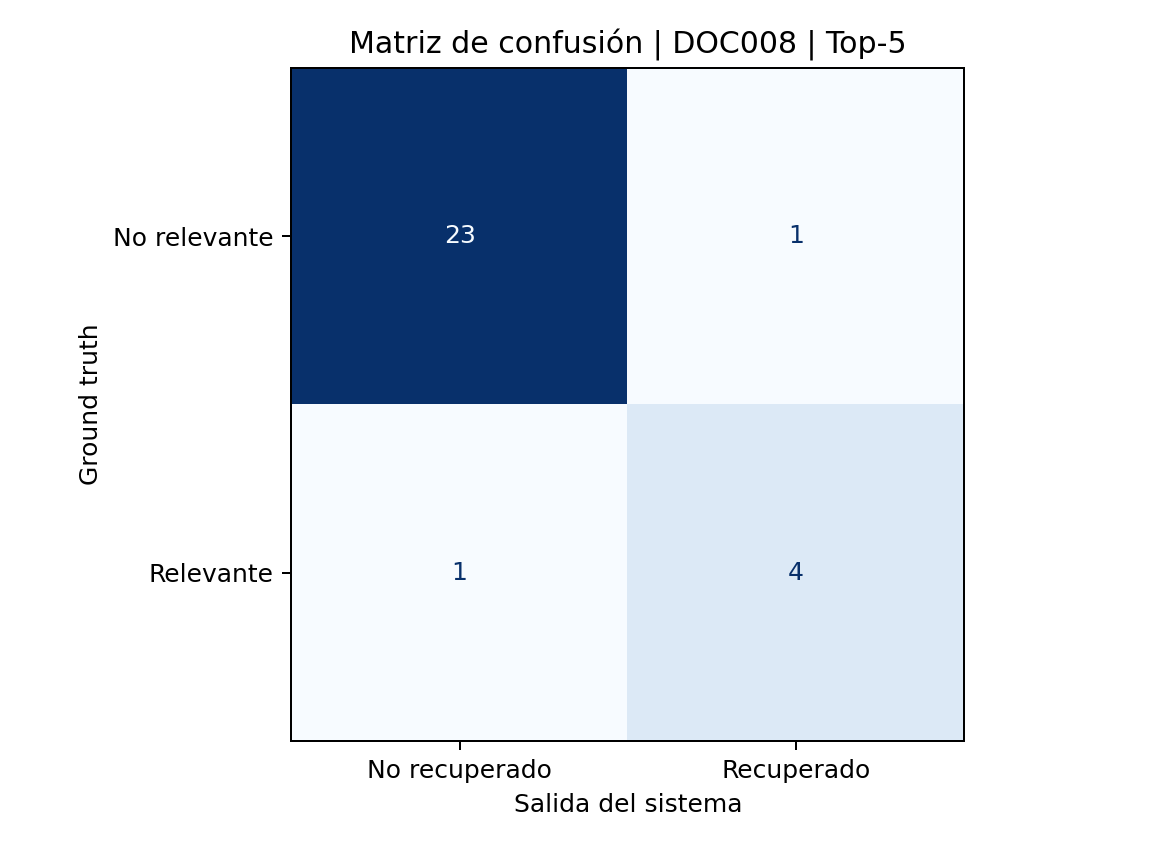

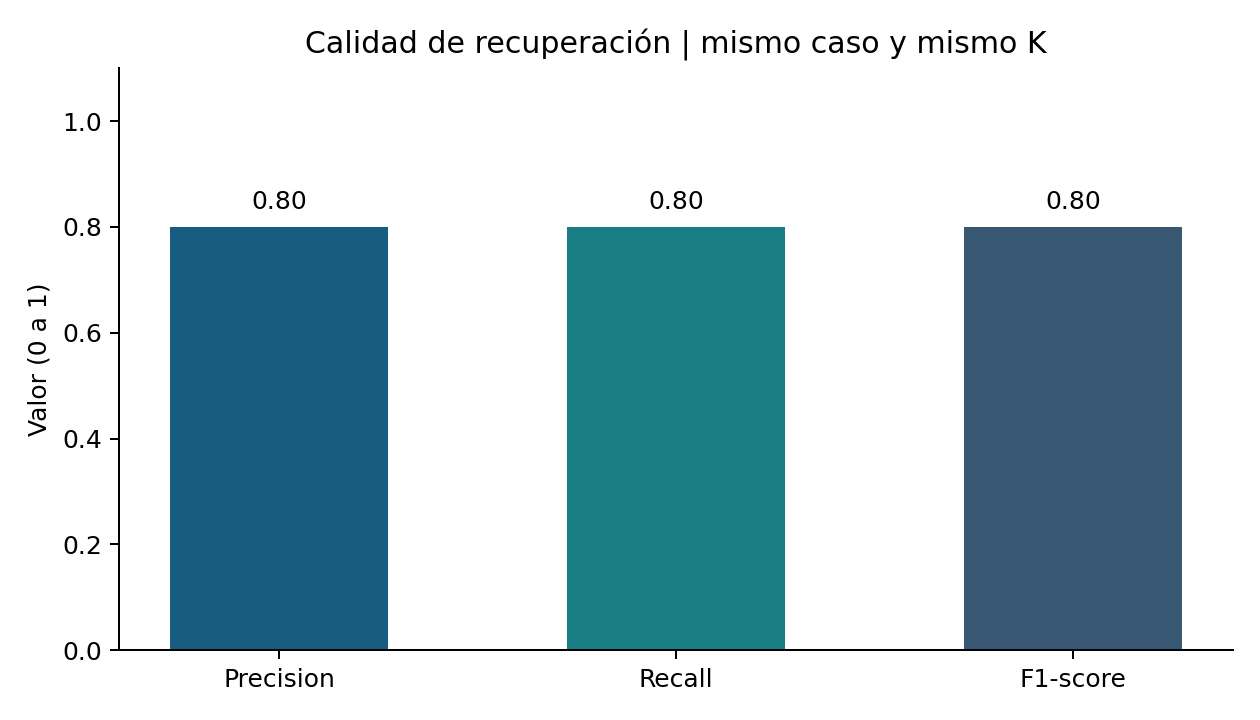

In [6]:
from IPython.display import display, Image
display(Image(filename=str(BASE/'evidencias/matriz_confusion.png')))
display(Image(filename=str(BASE/'evidencias/metricas.png')))

### Interpretación de la matriz y la gráfica
La matriz resume 4 verdaderos positivos, 23 verdaderos negativos, 1 falso positivo y 1 falso negativo.  
Los verdaderos negativos son documentos ajenos al tema que no aparecieron en las recomendaciones.  
Aunque son mayoría, no los usaría para afirmar que la búsqueda es excelente.  
La gráfica permite comparar las tres métricas con la misma escala y muestra su igualdad.  
En este caso me interesa tanto evitar resultados ajenos como recuperar el procedimiento omitido.  
La evaluación cubre una sola necesidad y no demuestra el desempeño en todo el repositorio.

## 5. Valor organizacional y mejoras propuestas
En una mesa de servicio, una recomendación útil puede evitar repetir diagnósticos y acercar procedimientos existentes. Un falso positivo consume tiempo; un falso negativo puede ocultar un paso de validación de datos. No se midió ahorro de tiempo ni resolución real.

Propondría comparar filtros de tema, normalización de variantes y recuperación híbrida con embeddings; también evaluar distintos valores de K sobre más consultas. Esas son propuestas futuras: **en esta actividad no se ajusta el recomendador**. Un K mayor puede mejorar recall, pero también añadir resultados irrelevantes.

Para producción agregaría versión, vigencia y permisos por rol, además de juicios de varios especialistas. Compararía variantes con un conjunto de evaluación independiente, sin escoger parámetros únicamente para que DOC009 aparezca en esta prueba.

### Reflexión final
Evaluar me permite separar una impresión de utilidad de un resultado que puedo revisar.  
La precisión muestra cuánto ruido recibe quien consulta y el recall revela información que falta.  
El F1 resume el equilibrio, pero no sustituye revisar qué documentos fueron omitidos.  
En una organización, esos errores pueden afectar el tiempo de atención y la calidad de las decisiones.  
Antes de cambiar el sistema, repetiría la evaluación con más necesidades y criterios claros.  
También mediría utilidad con usuarios reales, porque una coincidencia temática no garantiza una solución.